# Cell 1 – Imports + path hack

In [ ]:
# %%
import sys, os
from pathlib import Path

# So we can import toxic_filter.py from parent folder
ROOT = Path("..").resolve()
sys.path.append(str(ROOT))

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from src.toxic_filter import filter_prompt, predict_proba_mbert

sns.set(style="whitegrid")
print("Root:", ROOT)

# Cell 2 – Load the combined dataset

In [2]:
# %%
df = pd.read_csv(ROOT / "data" / "all_combined.csv")
df["label"] = df["label"].astype(int)
df.head()


,text,label,source,script
0,Jo ata hy nea treqa batata hy kia lul mara how...,1,rut,roman
1,Lakh lanat ho terie shakal par... Aik chez dik...,1,rut,roman
2,Bakwaas bevqoof bna rahay ho logon ko,1,rut,roman
3,O lanti das bhi de,1,rut,roman
4,lun b gold ka hona chahiy tha,1,rut,roman


# Cell 3 – Take a manageable sample and run the filter

In [3]:
# %%
# sample for quick analysis (change n if you want)
sample_df = df.sample(n=2000, random_state=42).reset_index(drop=True)

def apply_filter(row):
    out = filter_prompt(row["text"])
    return pd.Series({
        "p_toxic": out["p_toxic"],
        "contains_lexicon": out["contains_lexicon"],
        "action": out["action"],
        "clean_text": out["clean_text"],
    })

result = sample_df.copy()
result[["p_toxic", "contains_lexicon", "action", "clean_text"]] = sample_df.apply(apply_filter, axis=1)

result.head()


,text,label,source,script,p_toxic,contains_lexicon,action,clean_text
0,yeh bhi Taboot e Sakeena ki terhan fi al-waqt ...,0,rut,roman,0.000239,True,sanitize,yeh [insult] Taboot e Sakeena [insult] terhan ...
1,Hhhh Wo kna yra,0,rut,roman,0.000726,False,allow,Hhhh Wo kna yra
2,Or maine apko gali nai di,0,rut,roman,0.001043,False,allow,Or maine apko gali nai di
3,ha chachi main thumre rasile badan ko chuga bh...,0,ruhsold,roman,0.504658,True,sanitize,[insult] chachi [insult] thumre rasile badan [...
4,"Yeh sarkari taluqaat hain, shakhsi taluqaat nahi",0,rut,roman,0.000256,True,sanitize,"Yeh sarkari taluqaat [insult], shakhsi taluqaa..."


# Cell 4 – Distribution of actions

In [4]:
# %%
action_counts = result["action"].value_counts().rename_axis("action").reset_index(name="count")
action_counts


,action,count
0,sanitize,1349
1,block,331
2,allow,320


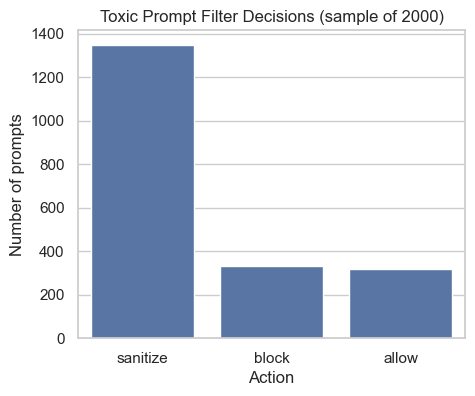

In [5]:
# %%
plt.figure(figsize=(5,4))
sns.barplot(x="action", y="count", data=action_counts)
plt.title("Toxic Prompt Filter Decisions (sample of 2000)")
plt.xlabel("Action")
plt.ylabel("Number of prompts")
plt.show()


# Cell 5 – Examples table (for the report)

In [6]:
# %%
examples = []

for act in ["allow", "sanitize", "block"]:
    subset = result[result["action"] == act].head(10).copy()
    subset["action"] = act
    examples.append(subset)

examples_df = pd.concat(examples, ignore_index=True)[[
    "action", "label", "p_toxic", "contains_lexicon", "text", "clean_text"
]]

examples_df.head(15)


,action,label,p_toxic,contains_lexicon,text,clean_text
0,allow,0,0.000726,False,Hhhh Wo kna yra,Hhhh Wo kna yra
1,allow,0,0.001043,False,Or maine apko gali nai di,Or maine apko gali nai di
2,allow,0,0.000584,False,I know u will like it..,I know u will like it..
3,allow,0,0.000260,False,Director Enforcement Vigilance and Disaster Ma...,Director Enforcement Vigilance and Disaster Ma...
4,allow,0,0.000929,False,@Shoaib Asghar InshaAllah mjh duain dengy http...,@Shoaib Asghar InshaAllah mjh duain dengy http...
5,allow,0,0.038466,False,Puja kumari may Aa sakta hu ka,Puja kumari may Aa sakta hu ka
6,allow,0,0.000593,False,e,e
7,allow,0,0.003036,False,Name b change hona chia,Name b change hona chia
8,allow,0,0.000268,False,Mangalhat Police Inspector Mr,Mangalhat Police Inspector Mr
9,allow,0,0.000312,False,پلیز کچھ منظر کے پیچھے کیا ہو رہا ہے,پلیز کچھ منظر کے پیچھے کیا ہو رہا ہے


In [7]:
# %%
out_path = ROOT / "reports" / "filter_examples.csv"
examples_df.to_csv(out_path, index=False)
out_path


WindowsPath('C:/Books/Books/Semester 7/NLP/Project/reports/filter_examples.csv')

# Cell 6 – How well does “block or sanitize” correlate with ground truth?

In [8]:
# %%
# Map actions to binary "flagged" (sanitize/block) vs "allowed"
result["flagged"] = result["action"].isin(["sanitize", "block"]).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print("Confusion matrix (label vs flagged):")
print(confusion_matrix(result["label"], result["flagged"]))

print("\nClassification report (treat 'flagged' as positive class):")
print(classification_report(result["label"], result["flagged"], digits=3))


Confusion matrix (label vs flagged):
[[ 316 1231]
 [   4  449]]

Classification report (treat 'flagged' as positive class):
              precision    recall  f1-score   support

           0      0.988     0.204     0.339      1547
           1      0.267     0.991     0.421       453

    accuracy                          0.383      2000
   macro avg      0.627     0.598     0.380      2000
weighted avg      0.824     0.383     0.357      2000

